In [1]:
from vasijas.config import load_config
from vasijas.evaluacion import (
    cargar_modelo_resnet18_evaluacion,
    contar_imagenes_segun_conjunto,
    convertir_clases_a_enteros,
    crear_loader_test_con_ruta,
    crear_tabla_predicciones_con_metadata,
    graficar_error_por_avance_y_origen,
    graficar_error_por_grupo,
    guardar_tabla_predicciones,
    indexar_metadata_por_ruta,
    obtener_clases_reales_y_predichas,
    obtener_identificadores_test,
    predecir_test_con_rutas,
    seleccionar_predicciones_por_borde_origen,
    validar_identificadores_metadata,
    validar_identificadores_split,
    validar_identificadores_test,
    validar_predicciones_test,
)
from vasijas.paths import ProjectPaths, ruta_relativa
from vasijas.metadata import cargar_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    crear_datasets_imagen_desde_metadata,
    crear_transformaciones_imagen,
    seleccionar_dispositivo_procesamiento,
)
from sklearn.metrics import classification_report

# Evaluación del modelo sobre el split de prueba

Este reporte aplica el modelo entrenado al conjunto de test persistido.
Las operaciones se implementan en `vasijas.evaluacion`; aquí se configuran los datos y el modelo, se eligen las acciones y se presentan sus resultados.

## Configuración

In [2]:
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)
DATA_DIR = PATHS.DATA_UNIFICADO_DIVIDIDO

MODELO_ENTRENADO = "model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth"
MODEL_PATH = PATHS.OUTPUT_MODELS / MODELO_ENTRENADO
PREDICTION_FILE = f"predicciones_test_{MODEL_PATH.stem}.csv"

PREDICTION_PATH = PATHS.OUTPUT_PREDICTIONS / PREDICTION_FILE
BATCH_SIZE = 16
TAMANO_IMAGEN = 224
DEVICE = seleccionar_dispositivo_procesamiento()

print(f"Dispositivo de procesamiento utilizado: {DEVICE}")
print(f"Modelo utilizado: {MODELO_ENTRENADO}")
print(f"Archivo de salida con predicciones (CSV): {PREDICTION_PATH.name}")

Dispositivo de procesamiento utilizado: cuda
Modelo utilizado: model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth
Archivo de salida con predicciones (CSV): predicciones_test_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.csv


## Preparación de los datos

Se conserva la división original y se aplica la normalización ImageNet sin aumentación. Cada predicción mantiene la ruta y el identificador de su imagen.

In [3]:
# Se reutiliza el split persistido: no se vuelve a dividir el dataset.
metadata_split = cargar_metadata(DATA_DIR)
validar_identificadores_split(metadata_split)

# Resize y normalización ImageNet, sin aumentación en test.
transformaciones = crear_transformaciones_imagen(
    ConfiguracionTransformacionesImagen(tamano_imagen=TAMANO_IMAGEN)
)
datasets_imagen = crear_datasets_imagen_desde_metadata(
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    transformacion_entrenamiento=transformaciones[0],
    transformacion_validacion=transformaciones[1],
    transformacion_test=transformaciones[2],
)
nombres_clases = datasets_imagen.class_names
metadata_por_ruta = indexar_metadata_por_ruta(metadata_split)

print("Clases:", ", ".join(nombres_clases))
print("Metadata indexada por rutas:", metadata_por_ruta.shape[0])

Clases: clase01, clase02, clase03, clase05, clase06, clase07, clase08, clase09, clase10, clase11
Metadata indexada por rutas: 20349


In [4]:
test_loader = crear_loader_test_con_ruta(
    subset=datasets_imagen.test,
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    batch_size=BATCH_SIZE,
    dispositivo=DEVICE,
)
cantidad_test = contar_imagenes_segun_conjunto(metadata_split, "test")

print(f"Imágenes de prueba: {cantidad_test}")

Imágenes de prueba: 3059


In [5]:
# Metadata original: sus columnas se conservan sin sustituir valores faltantes.
metadata_unificado = cargar_metadata(PATHS.DATA_UNIFICADO)
validar_identificadores_metadata(metadata_unificado)

identificadores_test = obtener_identificadores_test(metadata_split)
validar_identificadores_test(identificadores_test, metadata_unificado)

## Carga del modelo e inferencia

Se reconstruye ResNet18 desde los pesos locales y se verifica que tenga una salida por clase. Al terminar se comprueba que cada imagen de test tenga exactamente una predicción.

In [6]:
model = cargar_modelo_resnet18_evaluacion(
    ruta_modelo=MODEL_PATH,
    nombres_clases=nombres_clases,
    dispositivo=DEVICE,
)
print(f"Modelo cargado para evaluar {len(nombres_clases)} clases.")

Modelo cargado para evaluar 10 clases.


In [7]:
predicciones_test = predecir_test_con_rutas(
    modelo=model,
    test_loader=test_loader,
    metadata_por_ruta=metadata_por_ruta,
    nombres_clases=nombres_clases,
    dispositivo=DEVICE,
)
validar_predicciones_test(predicciones_test, metadata_split)

print(f"Predicciones verificadas: {len(predicciones_test)}")

Predicciones verificadas: 3059


## Resultados y exportación

Las predicciones se unen a la metadata original mediante `Identificador`. La tabla conserva sus columnas y valores faltantes e incorpora la clase predicha y el indicador de acierto.

In [8]:
tabla_predicciones = crear_tabla_predicciones_con_metadata(
    predicciones=predicciones_test,
    metadata_original=metadata_unificado,
)
guardar_tabla_predicciones(tabla_predicciones, PREDICTION_PATH)

print(f"Filas: {len(tabla_predicciones)} | Columnas: {len(tabla_predicciones.columns)}")
print(
    f"Aciertos: {int(tabla_predicciones['acierto'].sum())}/{len(tabla_predicciones)} ({tabla_predicciones['acierto'].mean():.2%})"
)
print(f"Tabla completa guardada en: {ruta_relativa(PREDICTION_PATH)}")
tabla_predicciones

Filas: 3059 | Columnas: 18
Aciertos: 2377/3059 (77.71%)
Tabla completa guardada en: output/predictions/predicciones_test_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.csv


,Identificador,Tiene asa,Tendencia Formal,Borde,Cuello,Cuerpo,Base,Clase Ana,Diametro Borde,Diametro Base,Altura Total,Cronologia,Ubicacion,id_perfil_completo,borde_origen,porcentaje_avance,clase_predicha,acierto
0,ba_191_4,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,completo,100.0,clase01,True
1,ba_191_4_base_10_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,10.0,clase01,True
2,ba_191_4_base_20_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,20.0,clase01,True
3,ba_191_4_base_30_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,30.0,clase01,True
4,ba_191_4_base_40_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,40.0,clase01,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3054,tu_91_3_tope_50_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,50.0,clase11,True
3055,tu_91_3_tope_60_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,60.0,clase11,True
3056,tu_91_3_tope_70_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,70.0,clase11,True
3057,tu_91_3_tope_80_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,80.0,clase11,True


La tabla `tabla_predicciones` contiene una fila por imagen de prueba con todas las columnas originales de `data/11.unificado/metadata.csv`, en el mismo orden, seguidas de `clase_predicha` y `acierto` (`True` si acertó, `False` si no). La unión se realiza mediante `Identificador`, valida una única coincidencia por imagen y conserva los valores faltantes de la metadata original. El CSV completo se guarda en `output/predictions/`. Para regenerarlo, ejecutar las celdas desde el principio.

In [9]:
tabla_predicciones_enteros = convertir_clases_a_enteros(tabla_predicciones)
tabla_predicciones_enteros

,Identificador,Tiene asa,Tendencia Formal,Borde,Cuello,Cuerpo,Base,Clase Ana,Diametro Borde,Diametro Base,Altura Total,Cronologia,Ubicacion,id_perfil_completo,borde_origen,porcentaje_avance,clase_predicha,acierto
0,ba_191_4,Si,IV,7,B,4,4,1,128,38,409,ibero,Baza,ba_191_4,completo,100.0,1,True
1,ba_191_4_base_10_centrado,Si,IV,7,B,4,4,1,128,38,409,ibero,Baza,ba_191_4,base,10.0,1,True
2,ba_191_4_base_20_centrado,Si,IV,7,B,4,4,1,128,38,409,ibero,Baza,ba_191_4,base,20.0,1,True
3,ba_191_4_base_30_centrado,Si,IV,7,B,4,4,1,128,38,409,ibero,Baza,ba_191_4,base,30.0,1,True
4,ba_191_4_base_40_centrado,Si,IV,7,B,4,4,1,128,38,409,ibero,Baza,ba_191_4,base,40.0,1,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3054,tu_91_3_tope_50_centrado,No,II,1,B,2,1,11,181,85,44,ibero,Tútugi,tu_91_3,tope,50.0,11,True
3055,tu_91_3_tope_60_centrado,No,II,1,B,2,1,11,181,85,44,ibero,Tútugi,tu_91_3,tope,60.0,11,True
3056,tu_91_3_tope_70_centrado,No,II,1,B,2,1,11,181,85,44,ibero,Tútugi,tu_91_3,tope,70.0,11,True
3057,tu_91_3_tope_80_centrado,No,II,1,B,2,1,11,181,85,44,ibero,Tútugi,tu_91_3,tope,80.0,11,True


In [10]:
tabla_predicciones_base = seleccionar_predicciones_por_borde_origen(
    tabla_predicciones_enteros, borde_origen="base"
)
y_true, y_pred = obtener_clases_reales_y_predichas(tabla_predicciones_base)
print(
    classification_report(
        y_true,
        y_pred,
    )
)

              precision    recall  f1-score   support

           1       0.94      0.94      0.94        36
           2       0.43      0.89      0.58        63
           3       0.69      0.63      0.66        99
           5       0.84      0.99      0.90        72
           6       0.71      0.50      0.59        72
           7       0.77      0.95      0.85        63
           8       0.86      0.72      0.78       378
           9       0.65      0.63      0.64        27
          10       0.77      0.82      0.79       477
          11       0.36      0.28      0.31       162

    accuracy                           0.72      1449
   macro avg       0.70      0.73      0.70      1449
weighted avg       0.73      0.72      0.72      1449



In [11]:
tabla_predicciones_tope = seleccionar_predicciones_por_borde_origen(
    tabla_predicciones_enteros, borde_origen="tope"
)
y_true, y_pred = obtener_clases_reales_y_predichas(tabla_predicciones_tope)
print(
    classification_report(
        y_true,
        y_pred,
    )
)

              precision    recall  f1-score   support

           1       0.72      0.72      0.72        36
           2       0.36      0.51      0.42        63
           3       0.80      0.74      0.77        99
           5       0.73      0.71      0.72        72
           6       0.57      0.54      0.56        72
           7       0.83      0.87      0.85        63
           8       0.83      0.77      0.80       378
           9       0.24      0.41      0.30        27
          10       0.98      0.97      0.97       477
          11       0.93      0.93      0.93       162

    accuracy                           0.82      1449
   macro avg       0.70      0.72      0.70      1449
weighted avg       0.84      0.82      0.83      1449



In [17]:
tabla_predicciones_enteros["Base"].value_counts().sort_index()

Base
1    1862
2    1045
3      76
4      76
Name: count, dtype: int64

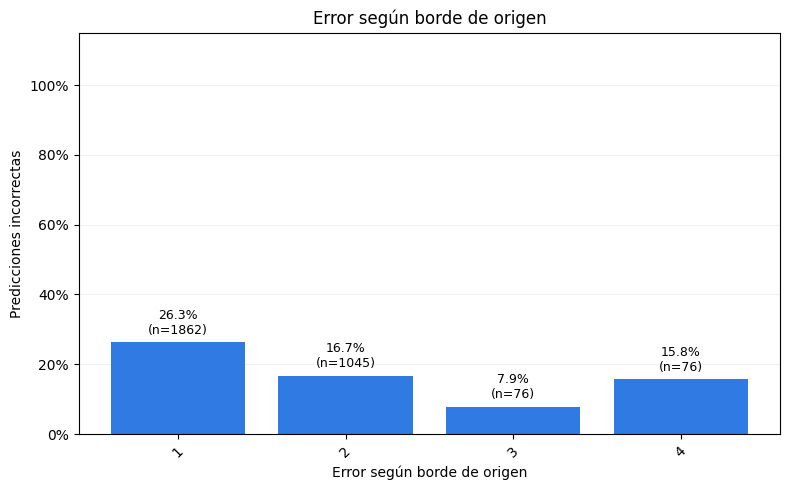

,Base,errores,imagenes,porcentaje_error
0,1,489,1862,26.262084
1,2,175,1045,16.746411
2,3,6,76,7.894737
3,4,12,76,15.789474


In [13]:
graficar_error_por_grupo(
    tabla_predicciones=tabla_predicciones,
    columna="Base",
    etiqueta="Error según borde de origen",
    tipo_grafico="barras",
)

In [18]:
tabla_predicciones_enteros["Borde"].value_counts().sort_index()

Borde
1     1159
3       19
4      285
7      779
8       57
9       38
11     437
13      38
14      95
15      38
17     114
Name: count, dtype: int64

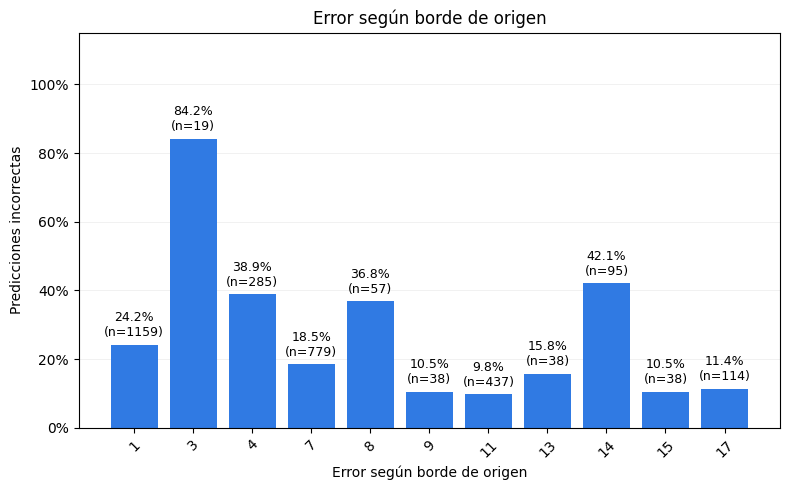

,Borde,errores,imagenes,porcentaje_error
0,1,280,1159,24.158758
1,3,16,19,84.210526
2,4,111,285,38.947368
3,7,144,779,18.485237
4,8,21,57,36.842105
5,9,4,38,10.526316
6,11,43,437,9.839817
7,13,6,38,15.789474
8,14,40,95,42.105263
9,15,4,38,10.526316


In [15]:
graficar_error_por_grupo(
    tabla_predicciones=tabla_predicciones,
    columna="Borde",
    etiqueta="Error según borde de origen",
    tipo_grafico="barras",
)

## Error según avance del corte y borde de origen

El gráfico compara **Tope** y **Base** para cada porcentaje de avance. Cada punto o barra representa **100 × errores / imágenes del grupo (avance, borde de origen)**. La línea horizontal discontinua indica el error observado en los **perfiles completos**, calculado con sus predicciones reales.

Seleccionar `TIPO_GRAFICO = "lineas"` para líneas con puntos o `TIPO_GRAFICO = "barras"` para barras agrupadas. La tabla `error_por_avance_y_origen` conserva los recuentos y porcentajes de cada grupo.

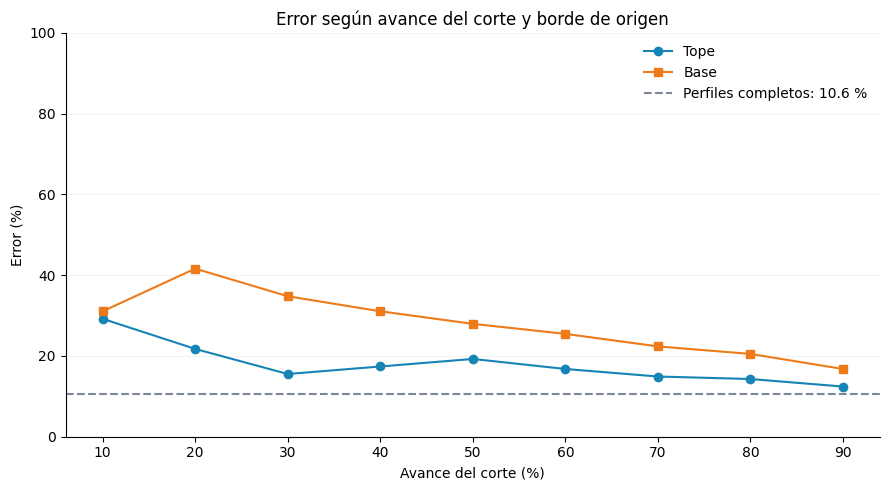

,porcentaje_avance,borde_origen,errores,imagenes,porcentaje_error
0,10.0,base,50,161,31.055901
1,10.0,tope,47,161,29.192547
2,20.0,base,67,161,41.614907
3,20.0,tope,35,161,21.739130
4,30.0,base,56,161,34.782609
5,30.0,tope,25,161,15.527950
6,40.0,base,50,161,31.055901
7,40.0,tope,28,161,17.391304
8,50.0,base,45,161,27.950311
9,50.0,tope,31,161,19.254658


In [19]:
TIPO_GRAFICO = "lineas"  # Opciones: "lineas" (con puntos) o "barras".

graficar_error_por_avance_y_origen(
    tabla_predicciones, tipo_grafico=TIPO_GRAFICO
)